In [1]:
using Plots, Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, ForwardDiff, LinearAlgebra, Wandb, DifferentialEquations, LineSearches, BlackBoxOptim, Random
# include("creation_model.jl")
# include("optimisation.jl")
# include("optimisation_constant_inhibition.jl")


#### In this script we are running an optmisation process for both muscles - TA and VL - in where there VthCa deactivation threshold is optmised to match experimental hysteresis

## Functions for the creation of the model excluding faciliation effect 

In [15]:
using Parameters

"""
ODE_motoneuron
Computation of the state variables: ϕ̊ = α(1-ϕ) - βϕ
Computation of the soma and dendrite membrane potentials using the previous calculated stated variables, etc.
"""

function ODE_motoneuron(t::Float64, vd::Float64, vs::Float64,
    gc::Float64, gld::Float64, gls::Float64, gCa::Float64, Cd::Float64,
    Cs::Float64,  αp::Float64,  βp::Float64, VthCa::Float64, gNa::Float64,
    αm::Float64, βm::Float64, Vth::Float64, gKf::Float64, gKs::Float64, αh::Float64, βh::Float64,
    αn::Float64, βn::Float64, αq::Float64, βq::Float64, γh::Float64,IF::Float64, m::Float64, h::Float64, 
    n::Float64, q::Float64, p::Float64, m0::Float64, h0::Float64, n0::Float64, q0::Float64, p0::Float64,
    t0::Float64, t1::Float64, SPIKE0::Int64, SPIKE1::Int64, exc_input,inh_input)
    
    
    ### AP 
    if vs > Vth && (t0 == -1 || (t-t0) > rp)   #initiation of the AP
        SPIKE0 = 1; t0=t; m0=m; h0=h; n0=n;q0=q;#p0=p
    
    elseif SPIKE0 == 1 && (t-t0) > pd    #end of the AP
        SPIKE0 = 0; t0=t; m0=m; h0=h; n0=n; q0=q;#p0=p
    
    end
    
    if SPIKE0 > 0 #AP (forward equations)
    
        @fastmath m = 1+(m0-1) * exp(-αm*(t-t0)) 
        @fastmath h = h0*exp(-βh*(t-t0)) 
        @fastmath n = 1+(n0-1)*exp(-αn*(t-t0)) 
        @fastmath q = 1+(q0-1)*exp(-αq*(t-t0)) 
    
    else # (backward equations)
        @fastmath m = m0*exp(-βm*(t-t0))
        @fastmath h = 1+(h0-1)*exp(-αh*(t-t0))  
        @fastmath n = n0*exp(-βn*(t-t0))
        @fastmath q = q0*exp(-βq*(t-t0))
    
    end
    
    
    # ### CA CHANNELS 
    
    if vs > Vth && (t1 == -1 ) # Initiate Ca spike with AP
        SPIKE1 = 1
        t1 = t
        p0 = p
        
    elseif (vs > Vth - VthCa)  && (t1 != -1) && (t - t1) > rp    
        SPIKE1 = 1
        t1 = t
        p0 = p
    
    elseif SPIKE1 == 1 && (t - t1) > pd
        SPIKE1 = 0
        t1 = t  
        p0 = p
    
    
    end
    
    
    if SPIKE1 > 0
        @fastmath p = 1 + (p0 - 1) * exp(-αp * (t - t1))
    else
        @fastmath p = p0 * exp(-βp * (t - t1))
    end
    
    
    
    @fastmath new_vs = (1/Cs)*(-gc*(vs-vd)-gls*(vs-EL)-gNa*m^3*h*(vs-ENa)-gKf*n^4*(vs-EK)-gKs*q^2*(vs-EK))
    
    @fastmath new_vd = (1/Cd)*(-gc*(vd-vs)-gld*(vd-EL)-γh*gCa*p*(vd-ECa)-exc_input*Ge*(vd-Ee)- IF*inh_input*Gi*(vd-Ei))
    
    return new_vd, new_vs, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1

end
    
    
    

"""
ode4(tspan, vd0, vs0, MN_i, state_params, exc_input,inh_input)
Computes voltage values for the soma and the dendrite for each time step
"""
function ode4(tspan, vd0, vs0, MN_i, state_params, exc_input,inh_input, MNs)
# unpack the variables that are in the MN list for one specififc motoneuron i

@unpack gc, gld, gls, gCa, Cd, Cs,  αp, βp, VthCa, gNa, αm, βm, Vth, gKf, gKs, αh, βh, αn, βn,
αq, βq, γh,IF= stringdict(MNs[MN_i])  

# state parameters

m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = state_params

N = length(tspan)-1 #number of steps
Vd = zeros(N) 
Vs = zeros(N)
Pt=zeros(N)
Mt=zeros(N)
Ht=zeros(N)
Nt=zeros(N)
Qt=zeros(N)

Vd[1] = vd0
Vs[1] = vs0
Pt[1] = p0
Mt[1] = m0
Ht[1] = h0
Nt[1] = n0
Qt[1] = q0


e_inp_prev=0
for i in 2:N #computation for time step
    ti = tspan[i-1] #previous time point
    hi = 0.05 #step size por integration, how far we look again in each interval
    vd = Vd[i-1] #voltage dendrite-value for the previous time step
    vs = Vs[i-1] #voltage soma-value for the previous time step
    e_inp = exc_input[_int(ti+1)] 
    i_inp = inh_input[_int(ti+1)]
    


    #Fourth-order Runge-Kutta method that solves differential equations with step-size of 0.05ms.

    vd1, vs1, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = ODE_motoneuron(ti, vd, vs, gc,
    gld, gls, gCa, Cd, Cs, αp,  βp, VthCa, gNa, αm, βm, Vth, gKf, gKs, αh, βh, αn, βn,
    αq, βq,γh, IF, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1, e_inp,i_inp)

    vd2, vs2, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = ODE_motoneuron(ti+0.5*hi,
    vd+0.5*hi*vd1, vs+0.5*hi*vs1, gc, gld, gls, gCa, Cd, Cs,  αp,  βp, VthCa, gNa, αm, βm, Vth, gKf,
    gKs, αh, βh, αn, βn, αq, βq, γh, IF, m, h , n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1, e_inp,i_inp)

    vd3, vs3, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = ODE_motoneuron(ti+0.5*hi,
    vd+0.5*hi*vd2, vs+0.5*hi*vs2, gc, gld, gls, gCa, Cd, Cs,  αp,  βp, VthCa, gNa, αm, βm, Vth, gKf,
    gKs, αh, βh, αn, βn, αq, βq, γh, IF, m,h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1, e_inp,i_inp)

    vd4, vs4, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = ODE_motoneuron(tspan[i],
    vd+hi*vd3, vs+hi*vs3, gc, gld, gls, gCa, Cd, Cs,  αp,  βp, VthCa, gNa, αm, βm, Vth, gKf,
    gKs, αh, βh, αn, βn, αq, βq, γh, IF, m,h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1, e_inp,i_inp)

    #to compute voltage for the next step
    Vd[i] = vd + (hi/6)*(vd1+2*vd2+2*vd3+vd4) #vd1 and vd4 are given a weight of 1 and vd2 and vd3 a weight of 2 because they are more reliable
    Vs[i] = vs + (hi/6)*(vs1+2*vs2+2*vs3+vs4)
    Pt[i] = p
    Mt[i] = m
    Ht[i] = h
    Nt[i] = n
    Qt[i] = q

    e_inp_prev= e_inp


end
state_params = (m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1)
return Vd, Vs, state_params,Pt, Mt, Ht, Nt, Qt
end


"""
spikes_from_aps(time_series, i) 
Returns spikes from the soma based on wheter the neuron voltage exceeds a specific threshold at a given time point (voltage t > threshold???)
* voltage_time_series = soma voltage returned by 'ode4' function (see function that runs simulation)
"""
function spikes_from_aps(voltage_time_series, i, MNs)
spikes = zeros(Int64, length(voltage_time_series))
for t = 2:length(voltage_time_series)-1
    # check if voltage is bigger than threshold (Vth)
    # Generate 1 or 0 from Boolean dependending on whether the element meets both conditions
    cond1 = voltage_time_series[t] > MNs[i][:Vth]
    cond2 = voltage_time_series[t-1] < voltage_time_series[t] > voltage_time_series[t+1]
    spikes[t]= _int(cond1 && cond2)
end
return spikes
end



spikes_from_aps

## Import experimental data TA

In [16]:
df_hyst = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hysteresis.csv",DataFrame; header=false);
hysteresis_exp = df_hyst[:, 1];

## Import experimental data VL

In [3]:
df_hyst = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hysteresisVL.csv",DataFrame; header=false);
hysteresis_exp = df_hyst[:, 1];

## Initiliase parameters for running simulation

In [17]:
######################  S-TYPE ##########################
#########################################################
nr_s = 87 #change to 89 if we are using VL, 87 for TA

# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = ones(nr_s)*22.0
βm = ones(nr_s)*13.0

αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4

αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1

αq_S = ones(nr_s)*1.5
βq_S = LinRange(0.025,0.038,nr_s) 

αp_D = 0.008
βp_D = LinRange(0.014,0.016,nr_s) 


Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

# at some point delete these things
γa=1.;
γh = ones(nr_s)*0.7#γn_new
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

#reversal potentials
EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 

#maximun conductances
Ge=0.6; Gi=0.5 ; 

#initial voltages
Vd0 = 0.; 
Vs0 = 0.;

#refractory period
rp=5.0; 

const step = 0.05;
_int(num) = floor(Int, num);

#Pulse duration [mS]
pd=1; 

ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

Vthca_S= zeros(nr_s);

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;


tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
pt_arr = zeros((nr_s, sim_time)); #storage
mt_arr = zeros((nr_s, sim_time)); #storage
ht_arr = zeros((nr_s, sim_time)); #storage
nt_arr = zeros((nr_s, sim_time)); #storage
qt_arr = zeros((nr_s, sim_time)); #storage
commoninput = tr; #needed for the run_sim() function


full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))
factor= 0.1 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length);


# Plots.plot(tr,grid=false,legend=false, linewidth=5)
# Plots.plot!(inh_input,grid=false,legend=false, linewidth=5)


30000-element Vector{Float64}:
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 ⋮
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001

## Function optim with constant inhibition

In [18]:
function object_function_constant_inh(VthCa,i)
    simulated_hysteresis, _ = simulate_hh_hysteresis_constant_inh(VthCa,i,MN_list)
    ssd = sum((hysteresis_exp[i] .- simulated_hysteresis).^2)
    return ssd 
end


function run_sim_optim_constant_inh(i)
    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, inh_input, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end


function firing_rates_max(spike_array,i)
    max_rates_mns=[]
    for i in 1: size(spike_array)[1]
        spike_pos=[]
        for j in 1:size(spike_array)[2]
            if spike_array[i,j]==1.0
                push!(spike_pos,j)
            end
        end
        ISI= diff(spike_pos);
        rates= 1 ./(ISI/20000)
        max_rates= maximum(rates)
        max_rates_mns=max_rates    
    end 
    max_rate_mn= max_rates_mns;
    return max_rate_mn;
    end



function simulate_hh_hysteresis_constant_inh(values_deac::Vector,i,MN_list) 
      
    MN_list[i][:VthCa] = values_deac[i]
    MNs= MN_list[i]
    spike_array, _ = run_sim_optim_constant_inh(i);

    amplitude=0.4;
    sim_length=560000 ;
    half_triang = div(sim_length, 2);  
    flat_line = fill(-0.1, 20000);
    up = range(-0.1, amplitude, length = half_triang + 1)  ;
    down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
    tr = vcat(flat_line, up[2:end], down[2:end], flat_line);
    hysteresis= []

    if any(spike_array[1, :] .== 1)     
        value_1= tr[findfirst(==(1),spike_array[1,:]),:] #force at the recruitment threshold
        value_2=  tr[findlast(==(1),spike_array[1,:]),:] #force at the derecruitment threshold
        hysteresis= (value_2[1]/value_1[1]).- 1
    else
        hysteresis=100 #random high value
    end

    max_firing_rates= [] #not relevant now firing_rates_max(spike_array,i) SOLVE THE CASE IN WHICH THERE ARE NO SPIKES
    
    return hysteresis, max_firing_rates
end


simulate_hh_hysteresis_constant_inh (generic function with 1 method)

#### TESTS to see the simulated hysteresis for one neuron for a give VthCa deactivation threshold

In [11]:
# ####### TEST SIMULATE HH HYSTERESIS #######
# ###########################################

# Vthca_S[11]=3


# function simulate_hh_hysteresis_constant_inh(VthCa::Vector,i,MN_list)   
#     MN_list[i][:VthCa] = Vthca_S[i]
#     MNs= MN_list[i]
#     spike_array, _ = run_sim_optim_constant_inh(i);

#     amplitude=0.4;
#     sim_length=560000 ;
#     half_triang = div(sim_length, 2);  
#     flat_line = fill(-0.1, 20000);
#     up = range(-0.1, amplitude, length = half_triang + 1)  ;
#     down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
#     tr = vcat(flat_line, up[2:end], down[2:end], flat_line);
#     hysteresis= []

#     if any(spike_array[1, :] .== 1)     
#         value_1= tr[findfirst(==(1),spike_array[1,:]),:] #force at the recruitment threshold
#         value_2=  tr[findlast(==(1),spike_array[1,:]),:] #force at the derecruitment threshold
#         hysteresis= (value_2[1]/value_1[1]).- 1
#     else
#         hysteresis=100 #random high value
#     end

#     max_firing_rates= [] #not relevant now firing_rates_max(spike_array,i) SOLVE THE CASE IN WHICH THERE ARE NO SPIKES
    
#     return hysteresis, max_firing_rates
# end


# hysteresis, max_firing_rates= simulate_hh_hysteresis_constant_inh(Vthca_S,11,MN_list)  

# println(hysteresis)

## Functions optim not constant inhibition (i.e.: push-pull)

In [19]:
# function object_function(γh,i)
#     penalty = 0
#     penalty_factor = 1e6  # Adjust

#     if γh[i] < 0. || γh[i] > 1.
#         penalty += penalty_factor * (0 - γh[i])^2
#     end

#     simulated_hysteresis, max_firing_rates = simulate_hh_hysteresis(γh,i)
#     ssd = sum((hysteresis_exp[i] .- simulated_hysteresis).^2)
    
#     return ssd + penalty
# end


# function run_sim_optim(i)

#     full_input = commoninput 
#     vd, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, full_input*factor, MNs)       
#     spikes = spikes_from_aps(vs, i, MNs)       
#     spike_arr = reshape(spikes, 1, length(spikes))
#     vs_arr[i,:] = vs
#     return spike_arr, vs_arr
# end


# function firing_rates_max(spike_array,i)

#         max_rates_mns=[]
#     for i in 1: size(spike_array)[1]
#         spike_pos=[]
#         for j in 1:size(spike_array)[2]
#             if spike_array[i,j]==1.0
#                 push!(spike_pos,j)
#             end
#         end
#         ISI= diff(spike_pos);
#         rates= 1 ./(ISI/20000)
#         max_rates= maximum(rates)
#         max_rates_mns=max_rates
        
#     end
    
#     max_rate_mn= max_rates_mns;
    
#     return max_rate_mn;
    
#     end


# function simulate_hh_hysteresis(γh::Vector,i)    
#     MN_list[i][:γh] = γh[i]

#     MNs= MN_list[i]

#     spike_array, vs_array = run_sim_optim(i);

#     amplitude=0.4;
#     sim_length=560000 ;
#     half_triang = div(sim_length, 2);  
#     flat_line = fill(-0.1, 20000);
#     up = range(-0.1, amplitude, length = half_triang + 1)  ;
#     down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
#     tr = vcat(flat_line, up[2:end], down[2:end], flat_line);
#     equiv_force_profile= (tr/maximum(tr))*nr_s

#     hysteresis= []

#     value_1= equiv_force_profile[findfirst(==(1),spike_array[1,:]),:] #force at the recruitment threshold
#     value_2=  equiv_force_profile[findlast(==(1),spike_array[1,:]),:] #force at the derecruitment threshold

#     if value_1 !== nothing
#         # Safe to use index
#     else
#         print(11111111)
#     end

#     if value_2 !== nothing
#         # Safe to use index
#     else
#         print(222222222)
#     end
#     hysteresis= (value_2/value_1).-1
#     # println(hysteresis)

#     max_firing_rates= firing_rates_max(spike_array,i)
    
#     return hysteresis, max_firing_rates
# end


# function compute_gradient_manual!(g::Vector{Float64}, γh::Vector{Float64}, i::Int; ε::Float64=1e-3)
#     γh_plus = copy(γh)
#     γh_minus = copy(γh)
    
#     γh_plus[i] += ε
#     γh_minus[i] -= ε

#     f_plus = BigFloat(object_function(γh_plus, i))
#     f_minus = BigFloat(object_function(γh_minus, i))

#     g[i] = (f_plus - f_minus) / (2 * ε)
# end

# function gradient_descent_optimization(γh_initial::Vector{Float64}, i::Int, learning_rate::Float64, max_iterations::Int, tolerance::Float64)
    
#     γh = copy(γh_initial)  # Initial parameters
#     g = zeros(Float64, length(γh))  # Gradient vector initialization
#     obj_value_prev = BigFloat(object_function(γh, i))  # Initial objective function value

#     for iter in 1:max_iterations
#         fill!(g, 0.0)  # Reset gradient vector
#         compute_gradient_manual!(g, γh, i)  # Compute gradient

        
#         for j in 1:length(γh)
#             γh[j] -= learning_rate * g[j]
#         end

#         # Ensure γh remains within bounds [0, 1]
#         γh = clamp.(γh, 0.0, 1.0)

#         # Compute new objective function value
#         obj_value_new = BigFloat(object_function(γh, i))


#         if abs(obj_value_new - obj_value_prev) < tolerance
#             println("Convergence achieved at iteration $iter")
#             break  
#         end

#         obj_value_prev = obj_value_new  # Update previous objective function value for next iteration

#         println("Iteration $iter, Objective Function Value: ", obj_value_new)
#     end

#     return γh  
# end



## Optim using libraries

In [20]:
global fitness_history = Float64[]
global smoothed_fitness_values = []

function objective_function(temporary_VCa, i, MN_list, hysteresis_exp)
    
    total_error = 0

    # println("vca         ",         temporary_VCa[i])
    # println("i         ",         i)


    hysteresis, _ = simulate_hh_hysteresis_constant_inh(temporary_VCa, i, MN_list)

    # println("hysteresis       ",         hysteresis)

    if hysteresis != 100  # 100 is a flag for no spikes
        error = (hysteresis - hysteresis_exp[i])^2
        total_error += error
    else
        total_error += 1.0
    end

    return total_error
end

function wrap_objective(x, i, Vthca_S, MN_list, hysteresis_exp) 

    temporary_VCa = copy(Vthca_S) 

    temporary_VCa[i] = x[1] #x is the candidate solution for VthCa for a given neuron

    ssd = objective_function(temporary_VCa, i, MN_list, hysteresis_exp)
    
    return ssd #total error, sum of squared distances
end


# Initialization

results = Dict()
for i in 1:nr_s
    println("Checking neuron ", i)

    if hysteresis_exp[i] < 0

        fitness_history = [];best_fitness_val = Inf;iteration = 0 #init

        while best_fitness_val >= 0.0005

            println("Starting optimization for Neuron ", i, " Iteration ", iteration)
            
            result=[]
            result = bboptimize(x -> wrap_objective(x, i, Vthca_S, MN_list, hysteresis_exp); SearchRange = [(0., 7.)], Method = :adaptive_de_rand_1_bin_radiuslimited, MaxTime = 300.0, PopulationSize = 100 + 10 * iteration, MutationRate = 0.8 + 0.05 * iteration, CrossoverRate = 0.8 + 0.05 * iteration  )

            best_params = best_candidate(result)
            best_fitness_val = best_fitness(result)
            iteration += 1

            println("Iteration ", iteration, ": Optimized Result for Neuron ", i, ": ", best_params, " with objective value: ", best_fitness_val)
            
            if best_fitness_val < 0.0005
                println("Neuron ", i, " optimization succeeded with objective value: ", best_fitness_val)
                results[i] = (minimizer = best_params, minimum = best_fitness_val)
                break

            elseif best_fitness_val > 0.0005
                println("Neuron ", i, " optimization did not reach the desired fitness, retrying...")
           
            end

            if iteration > 5
                println("Neuron ", i, " reached the maximum number of iterations.")
                results[i] = (minimizer = best_params, minimum = best_fitness_val)

                break
            end

            results[i] = (minimizer = best_params, minimum = best_fitness_val)

        end

    else
        println("Neuron ", i, " did not meet the conditions")
        results[i] = 0
    end
end


Checking neuron 1
Neuron 1 did not meet the conditions
Checking neuron 2
Neuron 2 did not meet the conditions
Checking neuron 3
Neuron 3 did not meet the conditions
Checking neuron 4
Neuron 4 did not meet the conditions
Checking neuron 5
Neuron 5 did not meet the conditions
Checking neuron 6
Neuron 6 did not meet the conditions
Checking neuron 7
Neuron 7 did not meet the conditions
Checking neuron 8
Neuron 8 did not meet the conditions
Checking neuron 9
Neuron 9 did not meet the conditions
Checking neuron 10
Neuron 10 did not meet the conditions
Checking neuron 11
Starting optimization for Neuron 11 Iteration 0
Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
7.91 secs, 2 evals, 1 steps, improv/step: 1.000 (last = 1.0000), fitness=0.081367974
15.34 secs, 4 evals, 2 steps, improv/step: 1.000 (last = 1.0000), fitness=0.000056120
23.08 

Excessive output truncated after 524310 bytes.

## Save new variables

In [21]:
results[50].minimizer[1]

4.1348004375453495

In [22]:
######### FOR TA #########

VthCa_newTA= zeros(1,nr_s)

for i in 1:nr_s
    if hysteresis_exp[i]<0
        VthCa_newTA[i]= results[i].minimizer[1]
    else
        VthCa_newTA[i]= 0
    end
end

In [9]:
######### FOR VL #########

VthCa_newVL= zeros(1,nr_s)

for i in 1:nr_s
    if hysteresis_exp[i]<0
        VthCa_newVL[i]= results[i].minimizer[1]
    else
        VthCa_newVL[i]= 0
    end
end

#### Accuracy for the TA

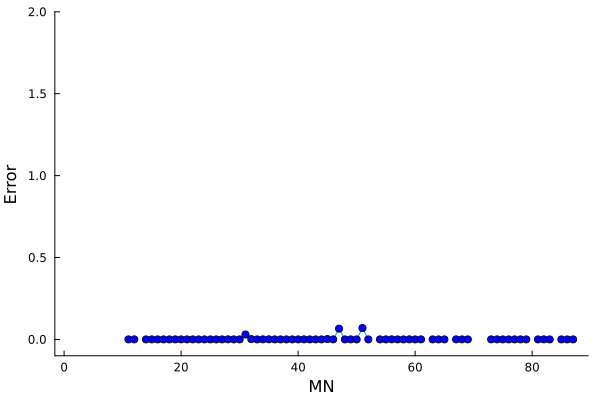

In [23]:
neuron_indices = Int[]
minimum_values = Float64[]

for (key, value) in results
    if isa(value, NamedTuple) && haskey(value, :minimum)
        push!(neuron_indices, key)
        push!(minimum_values, value.minimum)
    else
        push!(neuron_indices, key)
        push!(minimum_values, NaN) 
    end
end

# Sort by neuron index
sorted_indices = sortperm(neuron_indices)
sorted_neuron_indices = neuron_indices[sorted_indices]
sorted_minimum_values = minimum_values[sorted_indices]

# Plot the data
Plots.plot(sorted_neuron_indices, sorted_minimum_values, xlabel="MN", ylabel="Error", markershape=:circle, markercolor=:blue, line=:solid,grid=false,label=false,ylim=(-0.1, 2))

####  Accuracy for the VL

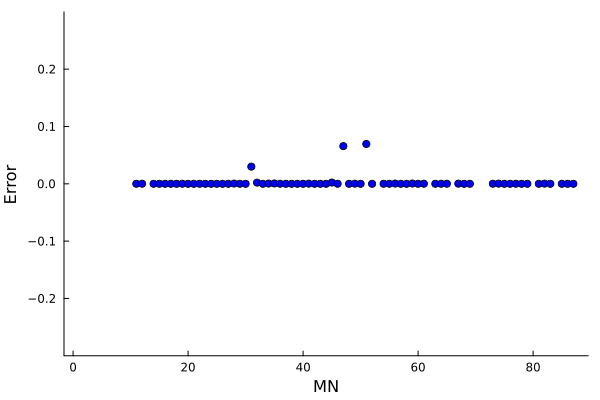

In [29]:
neuron_indices = Int[]
minimum_values = Float64[]

for (key, value) in results
    if isa(value, NamedTuple) && haskey(value, :minimum)
        push!(neuron_indices, key)
        push!(minimum_values, value.minimum)
    else
        push!(neuron_indices, key)
        push!(minimum_values, NaN) 
    end
end

# Sort by neuron index
sorted_indices = sortperm(neuron_indices)
sorted_neuron_indices = neuron_indices[sorted_indices]
sorted_minimum_values = minimum_values[sorted_indices]

# Plot the data
Plots.scatter(sorted_neuron_indices, sorted_minimum_values, xlabel="MN", ylabel="Error", markershape=:circle, markercolor=:blue, line=:solid,grid=false,label=false,ylim=(-0.3 ,0.3))

##### VTHCA distribution for TA

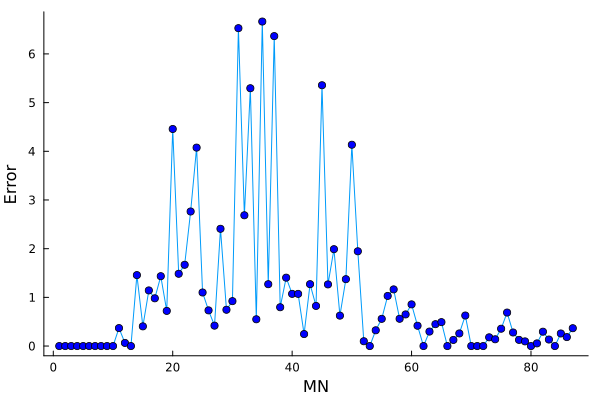

In [24]:
Plots.plot([1:87], VthCa_newTA[1,:], xlabel="MN", ylabel="Error", markershape=:circle, markercolor=:blue, line=:solid,grid=false,label=false)

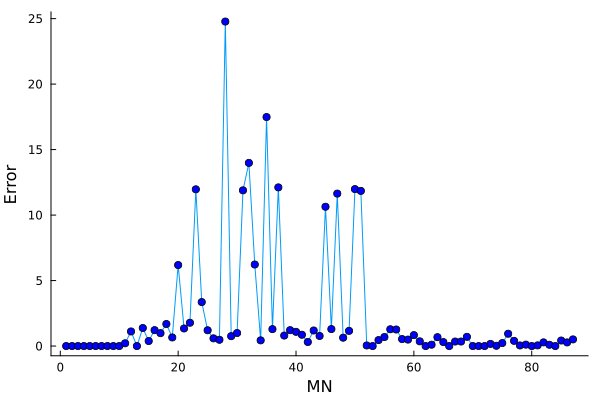

In [12]:
Plots.plot([1:87], VthCa_newTA[1,:], xlabel="MN", ylabel="Error", markershape=:circle, markercolor=:blue, line=:solid,grid=false,label=false)

##### VTHCA distribution for TA

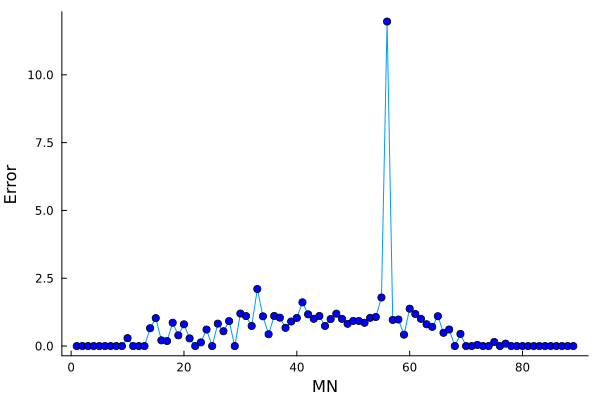

In [11]:
Plots.plot([1:89], VthCa_newVL[1,:], xlabel="MN", ylabel="Error", markershape=:circle, markercolor=:blue, line=:solid,grid=false,label=false)

## SAVE VARIABLES

In [25]:
# JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/VthCa_LAST_gamma07.jld2" VthCa_new
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/VthCa_TA_6sept.jld2" VthCa_newTA
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_TA_6sept.jld2" sorted_minimum_values
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_TA_6sept.jld2" sorted_neuron_indices

# JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/VthCaVL_gamma07_28Jul.jld2" VthCa_newVL